Constanza Pontillo 21.981.239-0

In [1]:
"Para empezar importamos las librerias que necesitamos"
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
"Elegimos una semilla"
rng = np.random.default_rng(seed = 33)

In [3]:
arreglo_temporal = np.linspace(0,10,500) #Con la funcion np.linspace nos da un intervalo de tiempo en este cado de 10 años y lo divide en 500 partes iguales
flujo_normalizado = np.ones(500)#Esto nos ayuda como un ideal de que cada flujo vale 1 en cada tiempo
ruido_gaussiano = rng.normal(loc=0,scale=0.002,size=(500))#Le agregamos ruido con una desviavion de 0.002
flujo_gaussiano = flujo_normalizado + ruido_gaussiano#Al sumarlo tenemos nuestro flujo de transito

In [4]:
mascara1 = (arreglo_temporal >= 4.5) & (arreglo_temporal <= 5.0)#Esta mascara nos dara el intervalo de tiempo que nos piden 
flujo_gaussiano[mascara1] -= 0.002#Disminuimos el flujo
mascara2 = (arreglo_temporal >= 7.0) & (arreglo_temporal <= 7.4)#Esta mascara nos dara el otro intervalo de tiempo que nos piden
flujo_gaussiano[mascara2] -= 0.015#Disminuimos el flujo
"Estas mascaras de todo los 500 tiempos que teniamos nos da solo los intervalos que realmente buscamos"

'Estas mascaras de todo los 500 tiempos que teniamos nos da solo los intervalos que realmente buscamos'

In [5]:
promedio = np.mean(flujo_gaussiano)#De nuestro flujo sacamos promedio con la funcion np.mean
desviacion = np.std(flujo_gaussiano)#De nuestro flujo sacamos la desviacion de los datos con la funcion np.std
condicion = promedio - 3 * desviacion#Establecemos una condicion
cumplen = flujo_gaussiano  < condicion#Elegimos aquellos que si cumplen la condicion anterior 

In [18]:
def curva_luz(tiempo, flujo): #Para nuestra funcion funcione necesita el timepo de transito y el flujo

    plt.figure(figsize=(12, 6))#Elegimos un tamaño para que se pueda ver mejor el grafico 
    
    plt.plot(tiempo, flujo, marker="*", color="navy",label="Flujo observado")#Hacemos el grafico de de la curvatura de la luz dando como variables el tiempo y el flujo, ademas agregamos color, maradores y nombre
    plt.plot(tiempo[cumplen],flujo[cumplen], marker="o", color="darkred",label="Cumplen condicion")#De igual manera filtramos con otros color y forma los datos que cumplen la condicion que establecimos
    
    plt.axhline(y=promedio, color="yellow", linestyle="--", label="Promedio")#Agregamos el promedio 
    plt.axhline(y=condicion, color="green", linestyle="--", label="Umbral de deteccion")#Agregamos el umbral

    plt.axvline(x=4.5, color='purple', linestyle='-')#Generamos linea verticales que demarcan los intervalos de interes en este caso de 4.5 - 5-0
    plt.axvline(x=5.0, color='purple', linestyle='-')

    plt.axvline(x=7.0, color='purple', linestyle='-')#Generamos linea verticales que demarcan los intervalos de interes aca de 7.0 -7.4
    plt.axvline(x=7.4, color='purple', linestyle='-')

    plt.xlabel("Tiempo",fontsize=14)#Le ponemos titulo a nuestro eje y
    plt.ylabel("Flujo",fontsize=14)#Le ponemos titulo a nuestro eje y
    plt.title("Curva de luz")#Le ponemos titulo a nuestro grafico

    plt.legend(fontsize=14)#Las legendas tendra un tamaño de letra de 14
    plt.grid(True)#Con grid(True) nos muestra en nuestro grafico una cudricula 
    plt.show()#Con esto mostramos nuestro grafico 
    

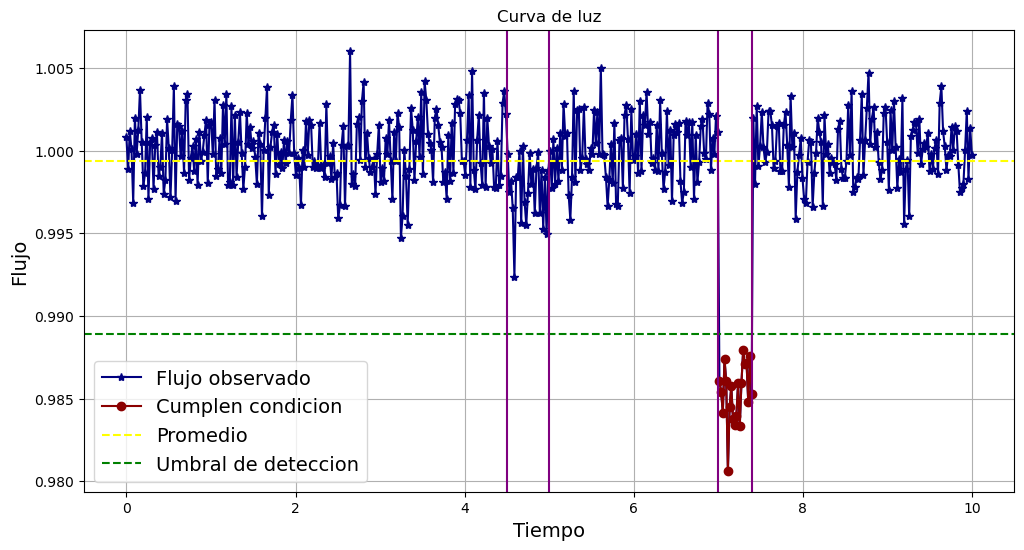

In [19]:
curva_luz(arreglo_temporal, flujo_gaussiano)